# Q2. Where do discounts cut into margin?

**Decision it informs:** a discount cap (per category, or one cap for all).

**Scope:** valid order items, January 2015 to September 2017. Bands use the discount rate actually applied
(`discount / sales`; the source's "6%" rows were applied at 5.5%, see the data-quality log).

**Method:** profit margin and quantity by discount band with confidence intervals; a test of whether extra
discount buys extra volume; then the what-if for a cap. **This is observational data:** discounts were not
randomly assigned by an experiment we control, so every result here is an association.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from IPython.display import Markdown, display

from scdd.db import connect, q, run_analysis, WINDOW_MONTHS
from scdd import style
from scdd.stats import ratio_bootstrap, save_findings

style.apply()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
con = connect()

items = q("""
    SELECT f.order_item_id, f.product_key, f.discount_rate, f.discount_rate_listed, f.sales, f.discount,
           f.item_total, f.profit, f.profit_ratio, f.quantity, p.category_name, p.product_name
    FROM fact_order_items f
    JOIN dim_product p USING (product_key)
    WHERE f.is_valid_order AND f.order_date < DATE '2017-10-01'
""", con)
bands = ["0-5%", "5-10%", "10-15%", "15-20%", "20-25%"]
items["band"] = pd.cut(items.discount_rate, [-0.001, 0.0499, 0.0999, 0.1499, 0.1999, 0.26], labels=bands)
print(f"{len(items):,} items; overall margin {items.profit.sum() / items.item_total.sum():.2%}; "
      f"discount spend {items.discount.sum():,.0f}")

164,572 items; overall margin 11.98%; discount spend 3,324,545


## 1. How discounts were handed out
Every listed discount rate appears on almost exactly the same number of items. That is the signature of a
rotation, not of discounts targeted at slow sellers, which is useful: it removes the most common confounder
(discounting what already sells badly).

In [2]:
per_rate = items.groupby("discount_rate_listed").size()
chi_uniform = stats.chisquare(per_rate.values)
print(f"{per_rate.size} listed rates; items per rate {per_rate.min():,} to {per_rate.max():,}; "
      f"chi-square test vs equal counts p = {chi_uniform.pvalue:.3f}")
shares = pd.crosstab(items.category_name, items.band, normalize="index")
print(f"Share of each category's items in the 20-25% band ranges {shares['20-25%'].min():.1%} to {shares['20-25%'].max():.1%}")

18 listed rates; items per rate 9,096 to 9,182; chi-square test vs equal counts p = 1.000
Share of each category's items in the 20-25% band ranges 8.4% to 14.0%


## 2. Margin and quantity by discount band
Source: `sql/analysis/p3_margin_by_band.sql`. Margin = profit / net revenue. The interval is a 95% bootstrap
interval (400 resamples of order items).

In [3]:
band = run_analysis("p3_margin_by_band.sql", con)
ci = [ratio_bootstrap(items.loc[items.band == b, "profit"].values, items.loc[items.band == b, "item_total"].values)
      for b in band.discount_band]
band["margin_ci_low"], band["margin_ci_high"] = zip(*ci)
band[["discount_band", "order_items", "discount_spend", "revenue", "profit", "profit_margin", "margin_ci_low",
      "margin_ci_high", "profit_per_gross_sales", "avg_quantity"]]

,discount_band,order_items,discount_spend,revenue,profit,profit_margin,margin_ci_low,margin_ci_high,profit_per_gross_sales,avg_quantity
0,0-5%,45748,"181,847.8600","8,926,923.5300","1,057,720.3400",0.1185,0.1135,0.1238,0.1161,2.1842
1,5-10%,36586,"482,616.3200","6,801,480.7800","843,136.8100",0.1240,0.1180,0.1294,0.1158,2.1818
2,10-15%,27360,"636,342.9900","4,818,918.6300","574,501.0000",0.1192,0.1136,0.1254,0.1053,2.1832
3,15-20%,36588,"1,203,358.4100","6,089,862.5800","716,002.0700",0.1176,0.1121,0.1232,0.0982,2.1799
4,20-25%,18290,"820,379.0200","2,826,558.6500","338,585.6700",0.1198,0.1124,0.1269,0.0928,2.1831


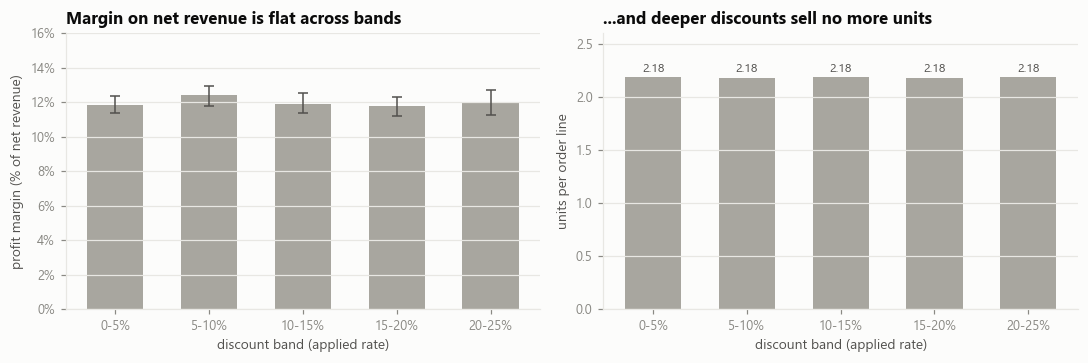

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
ax = axes[0]
x = np.arange(len(band))
err = [band.profit_margin - band.margin_ci_low, band.margin_ci_high - band.profit_margin]
ax.bar(x, band.profit_margin, color=style.GREY, width=0.6)
ax.errorbar(x, band.profit_margin, yerr=err, fmt="none", ecolor=style.INK_2, capsize=3, lw=1)
ax.set_xticks(x, band.discount_band); ax.set_xlabel("discount band (applied rate)")
ax.set_ylabel("profit margin (% of net revenue)"); style.pct(ax, decimals=0); ax.set_ylim(0, 0.16)
ax.set_title("Margin on net revenue is flat across bands")
ax = axes[1]
ax.bar(x, band.avg_quantity, color=style.GREY, width=0.6)
ax.set_xticks(x, band.discount_band); ax.set_xlabel("discount band (applied rate)")
ax.set_ylabel("units per order line"); ax.set_ylim(0, 2.6)
ax.set_title("...and deeper discounts sell no more units")
for xi, v in zip(x, band.avg_quantity):
    ax.text(xi, v + 0.05, f"{v:.2f}", ha="center", fontsize=8, color=style.INK_2)
fig.tight_layout()
style.save(fig, "q2_margin_quantity_by_band")
plt.show()

## 3. Tests
**(a) Margin above vs at-or-below 10%.** Weighted least squares of each item's profit ratio on an
"above 10%" flag, weighted by net revenue, reproduces the two margins exactly; robust (HC1) errors.

**(b) Margin vs discount rate (continuous)**, with category fixed effects.

**(c) Volume response.** Quantity per line is fixed at 1 for some products (safe, kayak, bike, cleat), so the
elasticity is estimated *within product* on the products whose quantity varies: log(quantity) on discount rate
with product fixed effects.

In [5]:
items["above10"] = (items.discount_rate > 0.10 + 1e-9).astype(int)
wls = smf.wls("profit_ratio ~ above10", items, weights=items.item_total).fit(cov_type="HC1")
m_lo = items.loc[items.above10 == 0, "profit"].sum() / items.loc[items.above10 == 0, "item_total"].sum()
m_hi = items.loc[items.above10 == 1, "profit"].sum() / items.loc[items.above10 == 1, "item_total"].sum()
margin_diff_ci = wls.conf_int().loc["above10"].values
print(f"(a) margin at/below 10%: {m_lo:.2%}; above 10%: {m_hi:.2%}; difference {wls.params['above10'] * 100:+.2f} pts "
      f"(95% CI {margin_diff_ci[0] * 100:+.2f} to {margin_diff_ci[1] * 100:+.2f}), p = {wls.pvalues['above10']:.3f}")

cont = smf.wls("profit_ratio ~ discount_rate + C(category_name)", items, weights=items.item_total).fit(cov_type="HC1")
print(f"(b) margin slope: {cont.params['discount_rate'] * 10:+.3f} pts of margin per +1 pt of discount... "
      f"i.e. {cont.params['discount_rate']:+.4f} per unit rate, p = {cont.pvalues['discount_rate']:.3f}")

varying = items.groupby("product_key").quantity.transform("nunique") > 1
vol = items[varying].copy()
vol["log_q"] = np.log(vol.quantity)
el = smf.ols("log_q ~ discount_rate + C(product_key)", vol).fit(cov_type="HC1")
beta, beta_ci = el.params["discount_rate"], el.conf_int().loc["discount_rate"].values
q_lo = items.loc[items.above10 == 0, "quantity"].mean(); q_hi = items.loc[items.above10 == 1, "quantity"].mean()
q_test = stats.ttest_ind(vol.loc[vol.discount_rate > 0.10 + 1e-9, "quantity"], vol.loc[vol.discount_rate <= 0.10 + 1e-9, "quantity"], equal_var=False)
print(f"(c) {varying.mean():.0%} of items are products whose quantity varies. Semi-elasticity of quantity to "
      f"the discount rate: {beta:+.3f} (95% CI {beta_ci[0]:+.3f} to {beta_ci[1]:+.3f}), p = {el.pvalues['discount_rate']:.2f}. "
      f"A 10-pt deeper discount is associated with {np.expm1(beta * 0.10):+.2%} units per line.")
print(f"    Units per line: {q_lo:.3f} at/below 10% vs {q_hi:.3f} above (Welch p on varying products = {q_test.pvalue:.2f})")

(a) margin at/below 10%: 12.10%; above 10%: 11.81%; difference -0.28 pts (95% CI -0.81 to +0.24), p = 0.287


(b) margin slope: -0.052 pts of margin per +1 pt of discount... i.e. -0.0052 per unit rate, p = 0.783


(c) 59% of items are products whose quantity varies. Semi-elasticity of quantity to the discount rate: -0.006 (95% CI -0.057 to +0.044), p = 0.81. A 10-pt deeper discount is associated with -0.06% units per line.
    Units per line: 2.183 at/below 10% vs 2.182 above (Welch p on varying products = 0.96)


## 4. Category drill-down
Source: `sql/analysis/p3_category_band.sql`. Is any category's margin hurt by deep discounts? Same WLS test per
category, with a Holm correction because 14 categories are tested at once.

In [6]:
cat = run_analysis("p3_category_band.sql", con)
pvals = []
for c in cat.category_name:
    sub = items[items.category_name == c]
    fit = smf.wls("profit_ratio ~ above10", sub, weights=sub.item_total).fit(cov_type="HC1")
    pvals.append(fit.pvalues["above10"])
cat["p_value"] = pvals
order = np.argsort(cat.p_value.values)
holm = np.empty(len(cat))
running = 0
for rank, i in enumerate(order):
    running = max(running, min(1, (len(cat) - rank) * cat.p_value.values[i]))
    holm[i] = running
cat["p_holm"] = holm
cat["margin_gap_pts"] = (cat.margin_above_10 - cat.margin_at_or_below_10) * 100
cat[["category_name", "order_items", "margin_at_or_below_10", "margin_above_10", "margin_gap_pts", "p_value", "p_holm",
     "qty_at_or_below_10", "qty_above_10", "discount_above_10_cap"]]

,category_name,order_items,margin_at_or_below_10,margin_above_10,margin_gap_pts,p_value,p_holm,qty_at_or_below_10,qty_above_10,discount_above_10_cap
0,Fishing,16580,0.1224,0.1226,0.0208,0.9775,1.0000,1.0000,1.0000,"206,125.6932"
1,Cleats,23477,0.1266,0.1211,-0.5514,0.4109,1.0000,3.0040,3.0008,"131,270.1676"
2,Camping & Hiking,13142,0.1150,0.1163,0.1373,0.8677,1.0000,1.0000,1.0000,"122,889.8068"
3,Cardio Equipment,11926,0.1062,0.1254,1.9255,0.0463,0.5556,3.0041,3.0129,"109,965.0795"
4,Women's Apparel,20089,0.1334,0.1095,-2.3952,0.0012,0.0167,2.9965,2.9917,"93,390.5000"
5,Water Sports,14855,0.1177,0.1120,-0.5749,0.4689,1.0000,1.0000,1.0000,"92,725.3731"
6,Men's Footwear,21233,0.1195,0.1195,0.0043,0.9928,1.0000,1.0000,1.0000,"85,883.0931"
7,Indoor/Outdoor Games,18445,0.1284,0.1122,-1.6212,0.0355,0.4612,2.9939,2.9991,"85,758.1830"
8,Shop By Sport,10506,0.1084,0.1144,0.5995,0.5580,1.0000,2.9889,2.9680,"38,765.6736"
9,Electronics,3024,0.1126,0.1309,1.8268,0.3312,1.0000,2.9952,2.9978,"11,257.1913"


## 5. What-if: cap discounts at X%
Source: `sql/analysis/p3_whatif_cap.sql` for the upper bound. For each item above the cap, the discount is cut to
the cap and **unit cost is held fixed**, so each currency unit of discount removed becomes a unit of profit.

Three readings, annualised from 33 months (× 12/33):
* **High: volume holds.** Buyers keep buying the same.
* **Central: the elasticity seen in the data.** Volume moves by `exp(beta × (cap − rate)) − 1`, with beta
  floored at 0 (a negative estimate would mean a cap *adds* volume, which we don't claim).
* **Low: stress case, price elasticity −1.5.** An assumption, not an estimate from this data: each 1% effective
  price rise loses 1.5% of the capped items' volume. It stands in for buyers who would not order at all without
  the discount, which this data cannot show (it only contains orders that happened).

Also reported: the **break-even** share of capped volume that could be lost before the cap stops paying.

In [7]:
def recovery(cap: float, beta_used: float | None = None, price_elasticity: float | None = None) -> float:
    a = items[items.discount_rate > cap + 1e-9]
    uplift = (a.discount_rate - cap) * a.sales               # extra net revenue = extra profit at fixed unit cost
    new_profit = a.profit + uplift
    if price_elasticity is not None:
        price_rise = (a.discount_rate - cap) / (1 - a.discount_rate)
        keep = np.clip(1 + price_elasticity * price_rise, 0, None)
    elif beta_used is not None:
        keep = np.exp(beta_used * (cap - a.discount_rate))
    else:
        keep = 1.0
    return float((new_profit * keep).sum() - a.profit.sum())

per_year = 12 / WINDOW_MONTHS
beta_central = max(beta, 0.0)
caps = np.round(np.arange(0, 0.26, 0.01), 2)
wi = run_analysis("p3_whatif_cap.sql", con)
wi["high_per_year"] = wi.profit_recovered_per_year
wi["central_per_year"] = [recovery(c, beta_used=beta_central) * per_year for c in wi.cap]
wi["low_per_year"] = [recovery(c, price_elasticity=-1.5) * per_year for c in wi.cap]
wi[["cap", "items_above_cap", "low_per_year", "central_per_year", "high_per_year", "breakeven_volume_loss"]].iloc[::5]

,cap,items_above_cap,low_per_year,central_per_year,high_per_year,breakeven_volume_loss
0,0.0000,155390,"659,501.6412","1,208,865.0903","1,208,865.0903",0.5021
5,0.0500,109669,"422,047.9492","712,210.2682","712,210.2682",0.4652
10,0.1000,73106,"239,900.7129","371,069.1107","371,069.1107",0.4166
15,0.1500,45726,"95,628.5872","139,145.4487","139,145.4487",0.3039
20,0.2000,9117,"23,305.8521","33,078.3011","33,078.3011",0.3385
25,0.2500,0,0.0000,0.0000,0.0000,0.0000


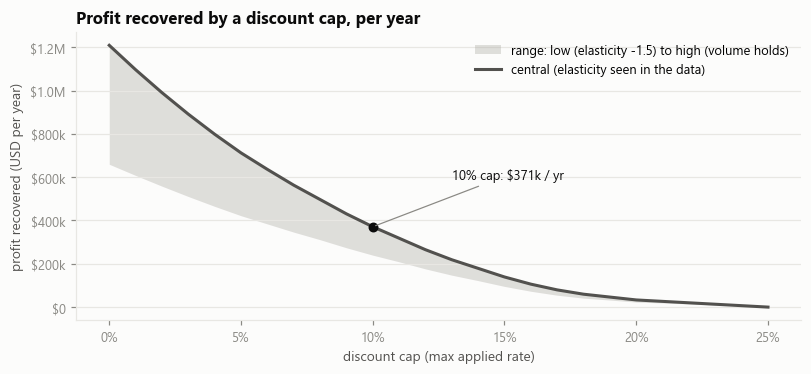

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.fill_between(wi.cap, wi.low_per_year, wi.high_per_year, color=style.GREY, alpha=0.35, lw=0,
                label="range: low (elasticity -1.5) to high (volume holds)")
ax.plot(wi.cap, wi.central_per_year, color=style.INK_2, lw=2, label="central (elasticity seen in the data)")
row10 = wi.loc[np.isclose(wi.cap, 0.10)].iloc[0]
ax.scatter([0.10], [row10.central_per_year], color=style.INK, zorder=3, s=30)
ax.annotate(f"10% cap: ${row10.central_per_year / 1e3:,.0f}k / yr", (0.10, row10.central_per_year),
            xytext=(0.13, row10.central_per_year + 2.2e5), fontsize=8.5, color=style.INK,
            arrowprops=dict(arrowstyle="-", color=style.INK_MUTED, lw=0.8))
style.pct(ax, axis="x"); style.money(ax)
ax.set_xlabel("discount cap (max applied rate)"); ax.set_ylabel("profit recovered (USD per year)")
ax.set_title("Profit recovered by a discount cap, per year")
ax.legend(loc="upper right")
style.save(fig, "q2_whatif_cap")
plt.show()

## Finding → number → decision

In [9]:
r10 = wi.loc[np.isclose(wi.cap, 0.10)].iloc[0]
sig = cat[cat.p_holm < 0.05]
sig_text = "; ".join(f"{r.category_name} {r.margin_at_or_below_10:.1%} → {r.margin_above_10:.1%} "
                     f"({r.margin_gap_pts:+.1f} pts, Holm p = {r.p_holm:.3f})" for r in sig.itertuples())
findings = {
    "overall_margin": items.profit.sum() / items.item_total.sum(),
    "discount_spend_window": items.discount.sum(),
    "items": len(items),
    "rates_items_min": int(per_rate.min()), "rates_items_max": int(per_rate.max()),
    "margin_by_band": dict(zip(band.discount_band, band.profit_margin)),
    "margin_ci_by_band": {b: [lo, hi] for b, lo, hi in zip(band.discount_band, band.margin_ci_low, band.margin_ci_high)},
    "qty_by_band": dict(zip(band.discount_band, band.avg_quantity)),
    "profit_per_gross_by_band": dict(zip(band.discount_band, band.profit_per_gross_sales)),
    "margin_at_or_below_10": m_lo, "margin_above_10": m_hi,
    "margin_diff_pts": wls.params["above10"] * 100, "margin_diff_ci_pts": list(margin_diff_ci * 100),
    "margin_diff_p": wls.pvalues["above10"],
    "qty_at_or_below_10": q_lo, "qty_above_10": q_hi, "qty_test_p": q_test.pvalue,
    "elasticity_beta": beta, "elasticity_ci": list(beta_ci), "elasticity_p": el.pvalues["discount_rate"],
    "categories_tested": len(cat), "categories_significant_holm": int((cat.p_holm < 0.05).sum()),
    "significant_categories": sig[["category_name", "margin_at_or_below_10", "margin_above_10", "margin_gap_pts",
                                   "p_holm", "discount_above_10_cap"]].to_dict(orient="records"),
    "cap": 0.10,
    "cap10_items_above": int(r10.items_above_cap),
    "cap10_share_items": r10.items_above_cap / len(items),
    "cap10_discount_above_cap_window": r10.profit_recovered_window,
    "cap10_high_per_year": r10.high_per_year,
    "cap10_central_per_year": r10.central_per_year,
    "cap10_low_per_year": r10.low_per_year,
    "cap10_breakeven_volume_loss": r10.breakeven_volume_loss,
    "whatif_by_cap": wi[["cap", "items_above_cap", "low_per_year", "central_per_year", "high_per_year",
                         "breakeven_volume_loss"]].to_dict(orient="records"),
}
save_findings("q2", findings)
display(Markdown(f"""
**Finding.** Deeper discounts buy no extra volume. Items discounted above 10% sell
**{q_hi:.2f}** units per line vs **{q_lo:.2f}** at or below 10% (within-product elasticity {beta:+.3f}, 95% CI
{beta_ci[0]:+.3f} to {beta_ci[1]:+.3f}, p = {el.pvalues['discount_rate']:.2f}). Their margin on net revenue is
{m_hi:.1%} vs {m_lo:.1%} (difference {wls.params['above10'] * 100:+.2f} pts, p = {wls.pvalues['above10']:.2f}).
Only {len(sig)} of {len(cat)} categories {'shows' if len(sig) == 1 else 'show'} a margin gap that survives Holm correction: {sig_text or 'none'}.
The rest don't, so one cap for all categories fits the evidence better than category-specific caps.

**Number.** {r10.items_above_cap:,.0f} items ({r10.items_above_cap / len(items):.0%}) were discounted above 10%; the part above
the cap was **${r10.profit_recovered_window:,.0f}** over 33 months. Capping at 10% recovers an estimated
**${r10.low_per_year / 1e3:,.0f}k to ${r10.high_per_year / 1e3:,.0f}k per year, central ${r10.central_per_year / 1e3:,.0f}k**. The cap
still pays unless more than **{r10.breakeven_volume_loss:.0%}** of the capped items' volume is lost.

**Decision.** Cap discounts at 10% across categories, first as a 4-week test in one market against a holdout,
because the data cannot show how many orders would not happen without the discount.
"""))


**Finding.** Deeper discounts buy no extra volume. Items discounted above 10% sell
**2.18** units per line vs **2.18** at or below 10% (within-product elasticity -0.006, 95% CI
-0.057 to +0.044, p = 0.81). Their margin on net revenue is
11.8% vs 12.1% (difference -0.28 pts, p = 0.29).
Only 1 of 14 categories shows a margin gap that survives Holm correction: Women's Apparel 13.3% → 10.9% (-2.4 pts, Holm p = 0.017).
The rest don't, so one cap for all categories fits the evidence better than category-specific caps.

**Number.** 73,106 items (44%) were discounted above 10%; the part above
the cap was **$1,020,440** over 33 months. Capping at 10% recovers an estimated
**$240k to $371k per year, central $371k**. The cap
still pays unless more than **42%** of the capped items' volume is lost.

**Decision.** Cap discounts at 10% across categories, first as a 4-week test in one market against a holdout,
because the data cannot show how many orders would not happen without the discount.
